# Topological and Structural Analysis of the Indian Stock Market

## Setting
Here, I am taking Nifty 200 for our analyses and interpretation works in 1-year window within the daily time-frame.

As suggested in the project problem, I am using the method of simple correlation and thresholding to create an **undirected** network of edges.

## Imports and Configuration

In [1]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import requests
import yfinance as yf
from scipy import stats

In [2]:
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
URL = "https://www.niftyindices.com/IndexConstituent/ind_nifty200list.csv"
DATA_DIR, FIG_DIR, TAB_DIR = "data", "figures", "tables"
for d in (DATA_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

In [4]:
start, end = "2025-11-08", "2026-11-08"  # 1 yr daily data
r_main = 0.6  # main correlation threshold r
max_missing = 0.02  # to drop a stock if more than 2% of dayas are missing
k_min = 3  # lower cut-off for the power law comparision

## Loading the Nifty 200 constituent list

In [5]:
FILE = f"{DATA_DIR}/nifty200list.csv"

if not os.path.exists(FILE):
    resp = requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    resp.raise_for_status()
    with open(FILE, "w") as f:
        f.write(resp.text)

In [6]:
meta = pd.read_csv(FILE)
meta.columns = meta.columns.str.strip()
meta["Symbol"] = meta["Symbol"].str.strip()
meta["Ticker"] = meta["Symbol"] + ".NS"  # NSE tickers on yfinance
meta = meta.drop_duplicates("Ticker").set_index("Ticker")
meta = meta.rename(columns={"Company Name": "name", "Industry": "sector"})
meta["sector"] = meta["sector"].fillna("unknown")

In [7]:
print("Constituents:", meta.shape[0], "stocks |", meta["sector"].nunique(), "sectors")
meta["sector"].value_counts()

Constituents: 200 stocks | 18 sectors


sector
Financial Services                48
Capital Goods                     24
Healthcare                        15
Automobile and Auto Components    14
Fast Moving Consumer Goods        14
Metals & Mining                   12
Consumer Services                 12
Information Technology            10
Oil Gas & Consumable Fuels         9
Power                              9
Consumer Durables                  8
Realty                             6
Chemicals                          5
Services                           4
Telecommunication                  4
Construction Materials             3
Construction                       2
Textiles                           1
Name: count, dtype: int64

**Note**: The CSV file is cached in the `data/` directory, so the server is queried only once.

## Downloading (cached) Adjusted Closing Prices

In [8]:
PRICE_FILE = f"{DATA_DIR}/adj_close_{start}_{end}.csv"

def download_adj_close(tickers, Start, enD, chunk=25, retries=3):
    frames, failed = [], []

    for i in range(0, len(tickers), chunk):
        batch = tickers[i:i + chunk]

        for attempt in range (1, retries + 1):
            try:
                raw = yf.download(batch, start=Start, end=enD, auto_adjust=False, progress=False, threads=False)

                frames.append(raw["Adj Close"])
                break
            except Exception as err:
                print(f"batch starting at {i}: attempt {attempt} failed ({err})")
                time.sleep(5 * attempt)
        else:
            failed.extend(batch)
    
    return pd.concat(frames, axis=1), failed

**Note**: In the `download_adj_close()` function, `auto_adjust=False` was required for the `Adj Close` column to be returned.

In [9]:
if os.path.exists(PRICE_FILE):
    prices = pd.read_csv(PRICE_FILE, index_col=0, parse_dates=True)
    print("Loaded cached prices:", prices.shape)
else:
    prices, failed_batches = download_adj_close(list(meta.index), start, end)
    prices.to_csv(PRICE_FILE)
    print("Downloaded:", prices.shape, "| tickers in failed batches:", failed_batches)

Loaded cached prices: (247, 200)


## Data Quality and Cleaning
We report every filter so the sample is transparent. Stocks with too many missing days (for examples, those stocks which are listed after the window began or suspended) are dropped.

Short gaps are forward-filled for at most 2 days.

In [10]:
prices = prices.sort_index().loc[start:end]
requested = meta.shape[0]
with_data = prices.dropna(axis=1, how="all").shape[1]

In [11]:
missing_frac = prices.isna().mean()
keep = missing_frac[missing_frac <= max_missing].index
dropped = sorted(set(prices.columns) - set(keep))

clean = prices[keep].ffill(limit=2).dropna(how="any")

In [12]:
quality = pd.Series({
    "Requested tickers": requested,
    "Tickers returned with data": with_data,
    "Kept after missing-data filter": len(keep),
    "Trading days after cleaning": clean.shape[0],
    "Total missing cells before cleaning (%)": round(100 * prices.isna().mean().mean(), 3)
}, name="value").to_frame()

print("Dropped tickers:", dropped)
quality

Dropped tickers: ['ICICIAMC.NS', 'MEESHO.NS', 'VAML.NS']


,value
Requested tickers,200.000
Tickers returned with data,200.000
Kept after missing-data filter,197.000
Trading days after cleaning,245.000
Total missing cells before cleaning (%),0.427


## Log returns and Pearson correlation matrix

We compute the daily logarithmic returns for each stock $i$ for preprocessing using the following equation: $$R_i(t)=\ln\left(\dfrac{P_i(t)}{P_i(t-1)}\right).$$

Pearson $\rho_{ij}$ is computed on the return series over the full window.

The checks confirm symmetry, unit diagonal and that the log return formula matches the difference of log prices.

In [13]:
log_returns = np.log(clean / clean.shift(1)).dropna()
assert np.allclose(log_returns, np.log(clean).diff().dropna())

corr = log_returns.corr(method="pearson")
assert np.allclose(corr.values, corr.values.T)
assert np.allclose(np.diag(corr.values), 1.0)

In [14]:
N, T = corr.shape[0], log_returns.shape[0]
print(f"Stocks N = {N}, return observations T = {T}")

# Market-mode disgnostic: how correlated are the stocks in general?
off = corr.values[np.triu_indices(N, k=1)]
print(f"Mean pairwise rho = {off.mean():.3f} | median = {np.median(off):.3f} | "
      f"90th percentile = {np.percentile(off, 90):.3f}")

Stocks N = 197, return observations T = 244
Mean pairwise rho = 0.279 | median = 0.274 | 90th percentile = 0.456


In [15]:
for r in [0.4, 0.5, 0.6, 0.7, 0.8]:
    print(f"  share of pairs with rho > {r}: {(off > r).mean():.2%}")

  share of pairs with rho > 0.4: 18.98%
  share of pairs with rho > 0.5: 5.73%
  share of pairs with rho > 0.6: 1.27%
  share of pairs with rho > 0.7: 0.34%
  share of pairs with rho > 0.8: 0.04%


In [16]:
# Random matrix check (Marchenko-Pastur) for noise in the correlation matrix
q = N / T
mp_edge = (1 + np.sqrt(q)) ** 2
eig = np.linalg.eigvalsh(corr.values)[::-1]
print(f"N/T = {q:.3f} | Marchenko-Pastur upper edge = {mp_edge:.3f}")
print(f"Largest eigenvalue = {eig[0]:.2f} (market mode) | eigenvalues above MP edge: {(eig > mp_edge).sum()}")

N/T = 0.807 | Marchenko-Pastur upper edge = 3.604
Largest eigenvalue = 60.21 (market mode) | eigenvalues above MP edge: 5


## Building the Unweighted Network
An edge $(i,j)$ exists iff $\rho_{ij}>r$. Self-loops are removed. Each node carries its sector and company name, which we use for interpretation and coloring.

In [17]:
SECTOR = meta["sector"].reindex(clean.columns)
NAME = meta["name"].reindex(clean.columns)

In [18]:
def build_graph(corr_matrix, r):
    A = (corr_matrix.values > r).astype(int)
    np.fill_diagonal(A, 0)
    A = pd.DataFrame(A, index=corr_matrix.index, columns=corr_matrix.columns)
    G = nx.from_pandas_adjacency(A)
    nx.set_node_attributes(G, SECTOR.to_dict(), "sector")
    nx.set_node_attributes(G, NAME.to_dict(), "name")
    return G

In [19]:
def homophily(G, attr="sector"):
    """Observed share of within-sector edges, its random-mixing expectation, and their ratio."""
    labels = pd.Series(nx.get_node_attributes(G, attr))
    edges = list(G.edges())
    obs = np.mean([G.nodes[u][attr] == G.nodes[v][attr] for u, v in edges]) if edges else np.nan
    expected = float(((labels.value_counts(normalize=True)) ** 2).sum())
    return obs, expected, obs / expected

In [20]:
G = build_graph(corr, r_main)

# Correctness checks
assert nx.number_of_selfloops(G) == 0
assert sum(d for _, d in G.degree()) == 2 * G.number_of_edges()  # handshake lemma

comps = sorted(nx.connected_components(G), key=len, reverse=True)
summary = {
    "Nodes N": G.number_of_nodes(),
    "Edges M": G.number_of_edges(),
    "Density": nx.density(G),
    "Average degree": 2 * G.number_of_edges() / G.number_of_nodes(),
    "Isolated nodes": nx.number_of_isolates(G),
    "Connected components": len(comps),
    "Giant component size": len(comps[0]),
    "Giant component fraction": len(comps[0]) / G.number_of_nodes()
}
if summary["Giant component fraction"] < 0.5:
    print(f"WARNING: at r = {r_main} the giant component covers only "
          f"{summary['Giant component fraction']:.0%} of stocks. Revisit `r_main` using Section D.")
pd.Series(summary, name=f"r = {r_main}").to_frame().round(4)

,r = 0.6
Nodes N,197.0000
Edges M,245.0000
Density,0.0127
Average degree,2.4873
Isolated nodes,92.0000
Connected components,105.0000
Giant component size,69.0000
Giant component fraction,0.3503


## Analysis A: *Degree Distribution*
Linear histogram, log-log histogram, and the complementary CDF $P(K \ge k)$, which is less noisy
than the histogram. A power law appears as a straight line on log-log axes. An exponential tail
bends downward on log-log axes and is straight on a semi-log plot. We compare both fits.

In [21]:
deg = pd.Series(dict(G.degree()), name="degree")
k_vals = np.arange(0, deg.max() + 1)
pk = deg.value_counts().reindex(k_vals, fill_value=0) / len(deg)
pk_pos = pk[pk > 0]
ccdf = pd.Series({k: (deg >= k).mean() for k in pk_pos.index if k > 0})

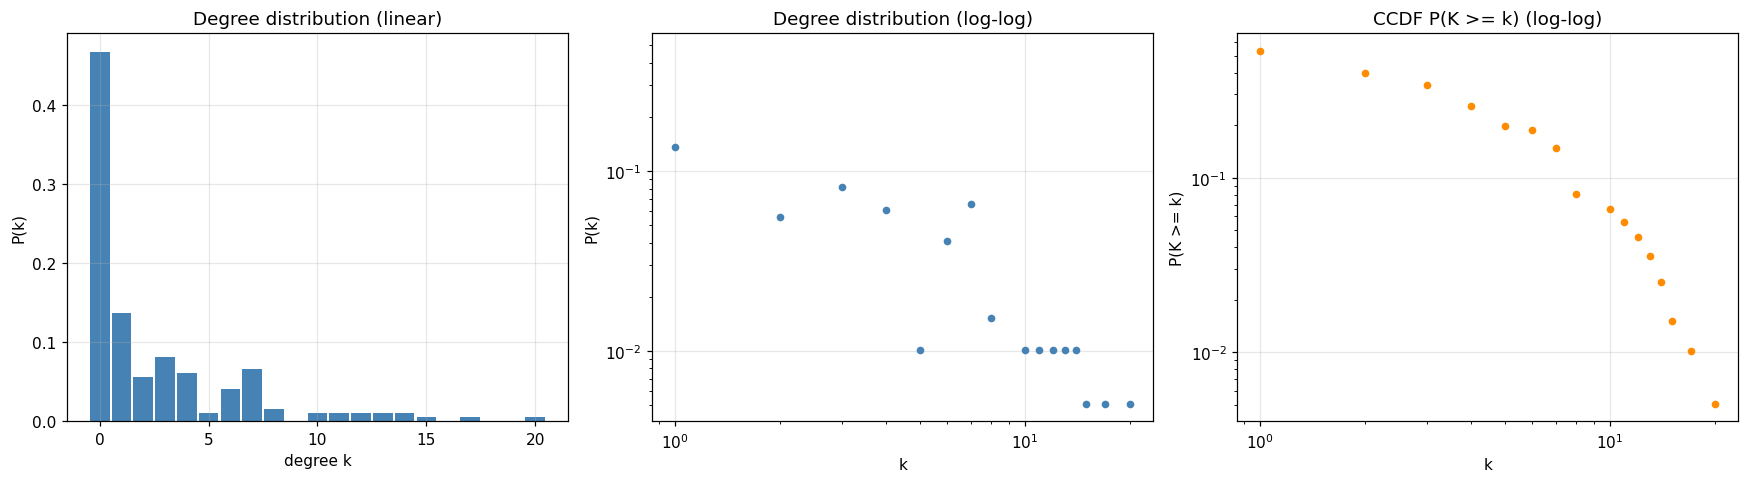

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].bar(pk.index, pk.values, width=0.9, color="steelblue")
ax[0].set(title="Degree distribution (linear)", xlabel="degree k", ylabel="P(k)")
ax[1].loglog(pk_pos.index, pk_pos.values, "o", ms=4, color="steelblue")
ax[1].set(title="Degree distribution (log-log)", xlabel="k", ylabel="P(k)")
ax[2].loglog(ccdf.index, ccdf.values, "o", ms=4, color="darkorange")
ax[2].set(title="CCDF P(K >= k) (log-log)", xlabel="k", ylabel="P(K >= k)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/degree_distribution.png", dpi=200)
plt.show()

In [23]:
# Goodness of fit on the tail (k >= k_min): exponential vs power law 
def fit_r2(x,y):
    """R^2 of a straight line fit. NaN if there are too few points to fit."""
    if len(x) < 3:
        return np.nan
    
    return stats.linregress(x,y).rvalue ** 2

c = ccdf[ccdf.index >= k_min]
r2_exp = fit_r2(c.index.values, np.log(c.values))
r2_pow = fit_r2(np.log(c.index.values), np.log(c.values))
tail = deg[deg >= k_min].values
alpha_mle = (1 + len(tail) / np.sum(np.log(tail / (k_min - 0.5)))) if len(tail) else np.nan  # discrete MLE approx.

fit = pd.Series({
    "Mean degree": deg.mean(),
    "Max degree": deg.max(),
    "R-squared, exponential fit (semi-log CCDF)": r2_exp,
    "R-squared, power-law fit (log-log CCDF)": r2_pow,
    f"Power-law exponent alpha (MLE, tail k from {k_min})": alpha_mle
}, name="value").to_frame().round(3)

print("Top 5 hubs by degree:")
print(deg.sort_values(ascending=False).head(5).to_string())
fit

Top 5 hubs by degree:
SHRIRAMFIN.NS    20
AMBUJACEM.NS     17
BAJAJFINSV.NS    15
INDIGO.NS        14
DLF.NS           14


,value
Mean degree,2.487
Max degree,20.000
"R-squared, exponential fit (semi-log CCDF)",0.989
"R-squared, power-law fit (log-log CCDF)",0.909
"Power-law exponent alpha (MLE, tail k from 3)",2.213


## Analysis B: *Top-10 Centrality Leaderboard*
Degree (how many peers a stock moves with), betweenness (how often a stock lies on shortest paths
between others, i.e. a bridge), and eigenvector (connection to other well-connected stocks).

In [24]:
deg_c = pd.Series(nx.degree_centrality(G))
btw_c = pd.Series(nx.betweenness_centrality(G, normalized=True))
try:
    eig_c = pd.Series(nx.eigenvector_centrality(G, max_iter=2000, tol=1e-8))
except:
    eig_c = pd.Series(nx.eigenvector_centrality_numpy(G))

In [25]:
def top10(series, label):
    s = series.sort_values(ascending=False).head(10)
    return pd.DataFrame({
        "Company": NAME.reindex(s.index).values,
        "Sector": SECTOR.reindex(s.index).values,
        label: s.values.round(4)
    }, index=s.index)

tables = [top10(deg_c, "Degree C"), top10(btw_c, "Betweenness C"), top10(eig_c, "Eigenvector C")]
for t in tables:
    display(t)

cent = pd.DataFrame({"degree": deg_c, "betweenness": btw_c, "eigenvector": eig_c})
print("Spearman rank correlation between centrality measures:")
display(cent.corr(method="spearman").round(3))

HEAVYWEIGHTS = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "ICICIBANK.NS", "INFY.NS",
                "BHARTIARTL.NS", "ITC.NS", "SBIN.NS"]
present = [h for h in HEAVYWEIGHTS if h in cent.index]
rank = cent.rank(ascending=False, method="min").reindex(present).astype("Int64")
print("Ranks of major index heavyweights (1 = most central, out of", G.number_of_nodes(), "nodes):")
display(rank)

,Company,Sector,Degree C
SHRIRAMFIN.NS,Shriram Finance Ltd.,Financial Services,0.1020
AMBUJACEM.NS,Ambuja Cements Ltd.,Construction Materials,0.0867
BAJAJFINSV.NS,Bajaj Finserv Ltd.,Financial Services,0.0765
INDIGO.NS,InterGlobe Aviation Ltd.,Services,0.0714
DLF.NS,DLF Ltd.,Realty,0.0714
ABCAPITAL.NS,Aditya Birla Capital Ltd.,Financial Services,0.0663
JIOFIN.NS,Jio Financial Services Ltd.,Financial Services,0.0663
GODREJPROP.NS,Godrej Properties Ltd.,Realty,0.0612
ASHOKLEY.NS,Ashok Leyland Ltd.,Capital Goods,0.0612
INDHOTEL.NS,Indian Hotels Co. Ltd.,Consumer Services,0.0561


,Company,Sector,Betweenness C
AMBUJACEM.NS,Ambuja Cements Ltd.,Construction Materials,0.0490
IREDA.NS,Indian Renewable Energy Development Agency Ltd.,Financial Services,0.0450
RECLTD.NS,REC Ltd.,Financial Services,0.0282
JIOFIN.NS,Jio Financial Services Ltd.,Financial Services,0.0265
PNB.NS,Punjab National Bank,Financial Services,0.0224
TATASTEEL.NS,Tata Steel Ltd.,Metals & Mining,0.0213
SHRIRAMFIN.NS,Shriram Finance Ltd.,Financial Services,0.0172
MAZDOCK.NS,Mazagoan Dock Shipbuilders Ltd.,Capital Goods,0.0134
INDIGO.NS,InterGlobe Aviation Ltd.,Services,0.0123
HINDALCO.NS,Hindalco Industries Ltd.,Metals & Mining,0.0102


,Company,Sector,Eigenvector C
SHRIRAMFIN.NS,Shriram Finance Ltd.,Financial Services,0.3579
BAJAJFINSV.NS,Bajaj Finserv Ltd.,Financial Services,0.2883
ABCAPITAL.NS,Aditya Birla Capital Ltd.,Financial Services,0.2762
DLF.NS,DLF Ltd.,Realty,0.2693
AMBUJACEM.NS,Ambuja Cements Ltd.,Construction Materials,0.2560
JIOFIN.NS,Jio Financial Services Ltd.,Financial Services,0.2536
INDHOTEL.NS,Indian Hotels Co. Ltd.,Consumer Services,0.2492
INDIGO.NS,InterGlobe Aviation Ltd.,Services,0.2284
GODREJPROP.NS,Godrej Properties Ltd.,Realty,0.2272
ASHOKLEY.NS,Ashok Leyland Ltd.,Capital Goods,0.2186


Spearman rank correlation between centrality measures:


,degree,betweenness,eigenvector
degree,1.000,0.790,0.941
betweenness,0.790,1.000,0.719
eigenvector,0.941,0.719,1.000


Ranks of major index heavyweights (1 = most central, out of 197 nodes):


,degree,betweenness,eigenvector
RELIANCE.NS,106,58,106
TCS.NS,17,35,73
HDFCBANK.NS,106,58,106
ICICIBANK.NS,106,58,106
INFY.NS,17,35,73
BHARTIARTL.NS,106,58,106
ITC.NS,106,58,106
SBIN.NS,30,58,67


## Visualization
The giant component, with isolated stocks removed for readability. Colour = sector, node size = degree.
The ten highest-degree stocks are labelled.

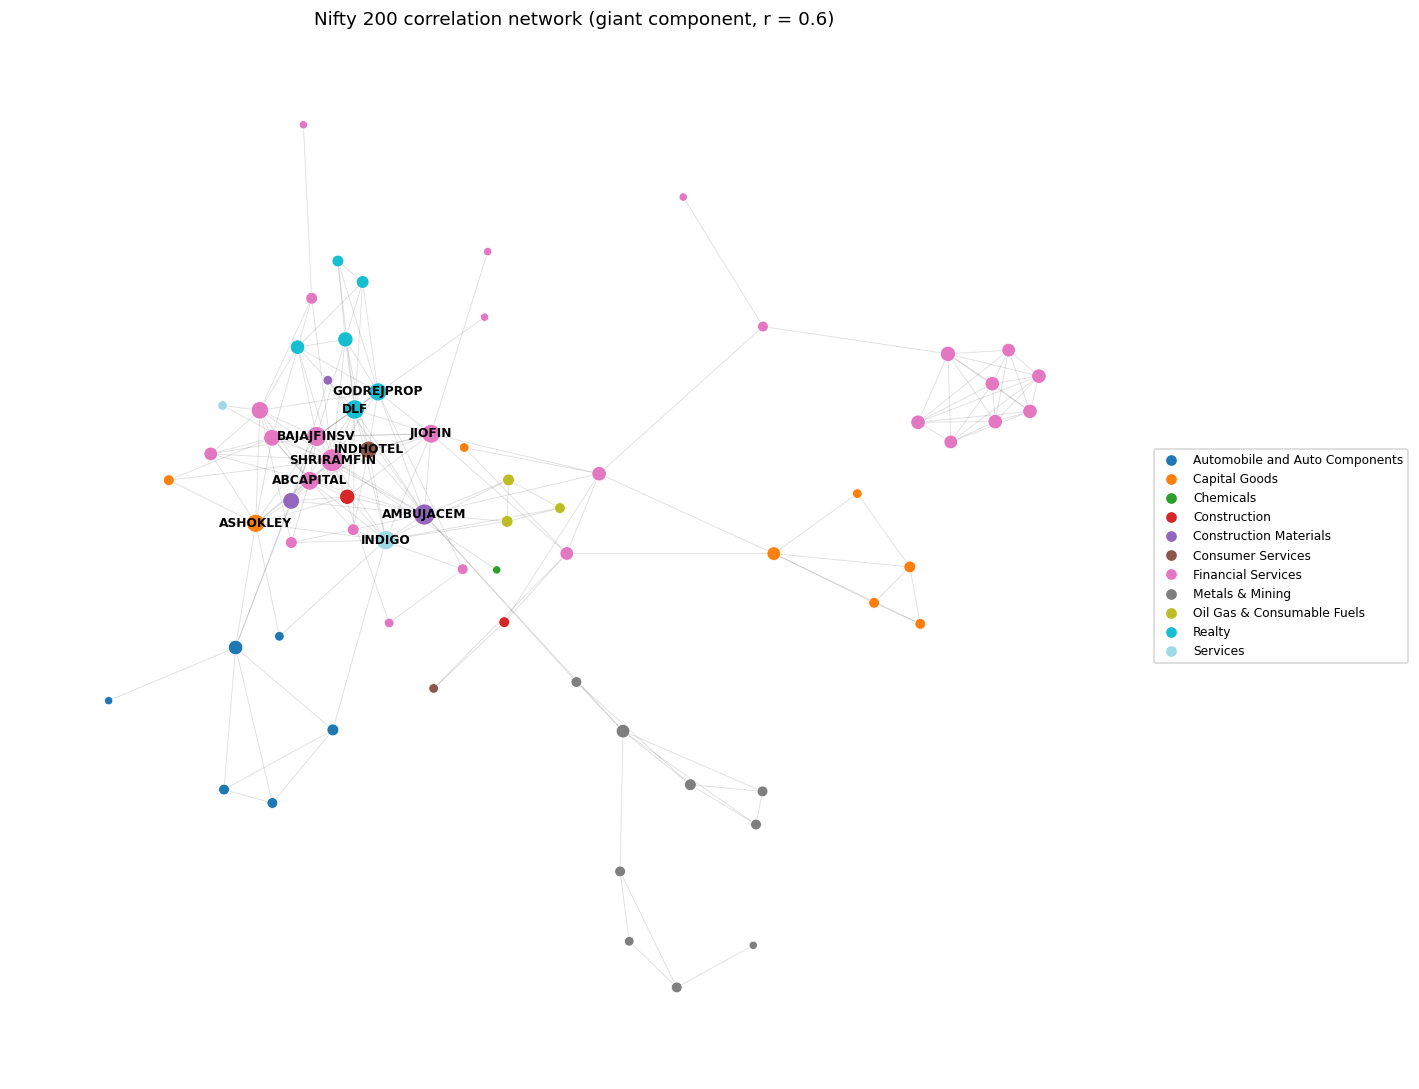

In [26]:
gc = G.subgraph(comps[0]).copy()
sectors = sorted(set(nx.get_node_attributes(gc, "sector").values()))
cmap = plt.get_cmap("tab20", max(len(sectors), 2))
color_of = {s: cmap(i) for i, s in enumerate(sectors)}

pos = nx.spring_layout(gc, seed=42, k=0.35)
node_colors = [color_of[gc.nodes[v]["sector"]] for v in gc]
node_sizes = [20 + 10 * gc.degree(v) for v in gc]

fig, ax = plt.subplots(figsize=(13,10))
nx.draw_networkx_edges(gc, pos, alpha=0.12, width=0.6, ax=ax)
nx.draw_networkx_nodes(gc, pos, node_color=node_colors, node_size=node_sizes,
                       edgecolors="white", linewidths=0.5, ax=ax)
hubs = sorted(gc.degree, key=lambda x: x[1], reverse=True)[:10]
nx.draw_networkx_labels(gc, pos, {v:v.replace(".NS", "") for v, _ in hubs},
                        font_size=8, font_weight="bold", ax=ax)
handles = [plt.Line2D([], [], marker="o", ls="", color=color_of[s], label=s) for s in sectors]

ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8, ncol=1)
ax.set_title(f"Nifty 200 correlation network (giant component, r = {r_main})")
ax.axis("off")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/network_giant_component.png", dpi=200, bbox_inches="tight")
plt.show()

## Analysis C: *Local Clustering Coefficient and Sector Homophily*
Average clustering is compared with a random graph $G(n,m)$ of the same size, since a high value only means something relative to the baseline. 

Sector homophily compares the observed share of within-sector edges with the random-mixing expectation $\sum_s p_s^2$, and a permutation test shuffles sector labels to obtain a p-value.

In [27]:
avg_clust = nx.average_clustering(G)
trans = nx.transitivity(G)
n_nodes, n_edges = G.number_of_nodes(), G.number_of_edges()
rand_cc = np.array([nx.average_clustering(nx.gnm_random_graph(n_nodes, n_edges, seed=s))
                    for s in range(200)])
print(f"Average clustering (observed)      = {avg_clust:.4f}")
print(f"Transitivity (observed)            = {trans:.4f}")
print(f"Average clustering, random G(n,m)  = {rand_cc.mean():.4f} ± {rand_cc.std():.4f}")

obs, expected, ratio = homophily(G)
print(f"\nWithin-sector edge share (observed) = {obs:.3f}")
print(f"Expected under random mixing         = {expected:.3f}")
print(f"Homophily ratio (observed/expected)  = {ratio:.2f}")

def permutation_test(G, attr="sector", n_perm=2000, seed=0):
    labels = nx.get_node_attributes(G, attr)
    nodes = list(labels)
    vals = np.array([labels[v] for v in nodes], dtype=object)
    idx = {v: i for i, v in enumerate(nodes)}
    E = np.array([(idx[u], idx[v]) for u, v in G.edges()])
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for b in range(n_perm):
        perm = rng.permutation(vals)
        null[b] = np.mean(perm[E[:, 0]] == perm[E[:, 1]])
    observed = np.mean(vals[E[:, 0]] == vals[E[:, 1]])
    p_value = (np.sum(null >= observed) + 1) / (n_perm + 1)
    return null, p_value

null_dist, p_val = permutation_test(G)
print(f"Permutation p-value (within-sector share ≥ observed) = {p_val:.4f}")
print(f"Null mean = {null_dist.mean():.3f}, null 95th percentile = {np.percentile(null_dist, 95):.3f}")

# Per-sector structure
s_ser = pd.Series(nx.get_node_attributes(G, "sector"))
rows = []
for s in s_ser.unique():
    members = s_ser.index[s_ser == s]
    n_s = len(members)
    internal = G.subgraph(members).number_of_edges()
    possible = n_s * (n_s - 1) / 2
    endpoints = sum(d for _, d in G.degree(members))
    rows.append({"sector": s, "stocks": n_s, "internal edges": internal,
                 "internal density": internal / possible if possible else np.nan,
                 "within-sector share of endpoints": 2 * internal / endpoints if endpoints else np.nan})
sector_tab = pd.DataFrame(rows).sort_values("stocks", ascending=False).set_index("sector")
display(sector_tab.round(3))

# Triangles: do closed triads stay inside one sector?
tris = [c for c in nx.enumerate_all_cliques(G) if len(c) == 3]
if tris:
    same = sum(len({G.nodes[v]["sector"] for v in t}) == 1 for t in tris)
    print(f"Triangles = {len(tris)} | all three stocks in the same sector: {same} ({same / len(tris):.1%})")
else:
    print("No triangles at this threshold.")

Average clustering (observed)      = 0.2684
Transitivity (observed)            = 0.5361
Average clustering, random G(n,m)  = 0.0094 ± 0.0069

Within-sector edge share (observed) = 0.633
Expected under random mixing         = 0.105
Homophily ratio (observed/expected)  = 6.02
Permutation p-value (within-sector share ≥ observed) = 0.0005
Null mean = 0.100, null 95th percentile = 0.143


,stocks,internal edges,internal density,within-sector share of endpoints
sector,,,,
Financial Services,47,66,0.061,0.717
Capital Goods,24,15,0.054,0.638
Healthcare,15,0,0.000,NaN
Automobile and Auto Components,14,7,0.077,0.700
Fast Moving Consumer Goods,14,1,0.011,1.000
Metals & Mining,11,13,0.236,0.812
Consumer Services,11,0,0.000,0.000
Information Technology,10,27,0.600,1.000
Oil Gas & Consumable Fuels,9,4,0.111,0.615


Triangles = 309 | all three stocks in the same sector: 155 (50.2%)


## Analysis D: *Threshold Sensitivity (the "What if" Study)*
The pipeline is re-run for a range of $r$.  
We track edges, giant-component size, average shortest path length (computed inside the giant component, since the full graph is disconnected), clustering, and homophily.

,edges,density,isolated,components,giant size,giant fraction,avg path (giant),avg clustering,homophily ratio
r,,,,,,,,,
0.30,8219,0.426,0,1,197,1.000,1.673,0.786,1.723
0.35,5760,0.298,1,3,194,0.985,1.929,0.734,2.051
0.40,3664,0.190,9,12,184,0.934,2.342,0.633,2.440
0.45,2056,0.106,23,30,152,0.772,2.275,0.573,3.000
0.50,1107,0.057,41,52,126,0.640,2.499,0.414,3.560
0.55,514,0.027,72,83,91,0.462,2.640,0.340,4.685
0.60,245,0.013,92,105,69,0.350,3.579,0.268,6.022
0.65,113,0.006,119,138,11,0.056,2.218,0.206,8.003
0.70,66,0.003,143,158,8,0.041,1.786,0.154,8.509


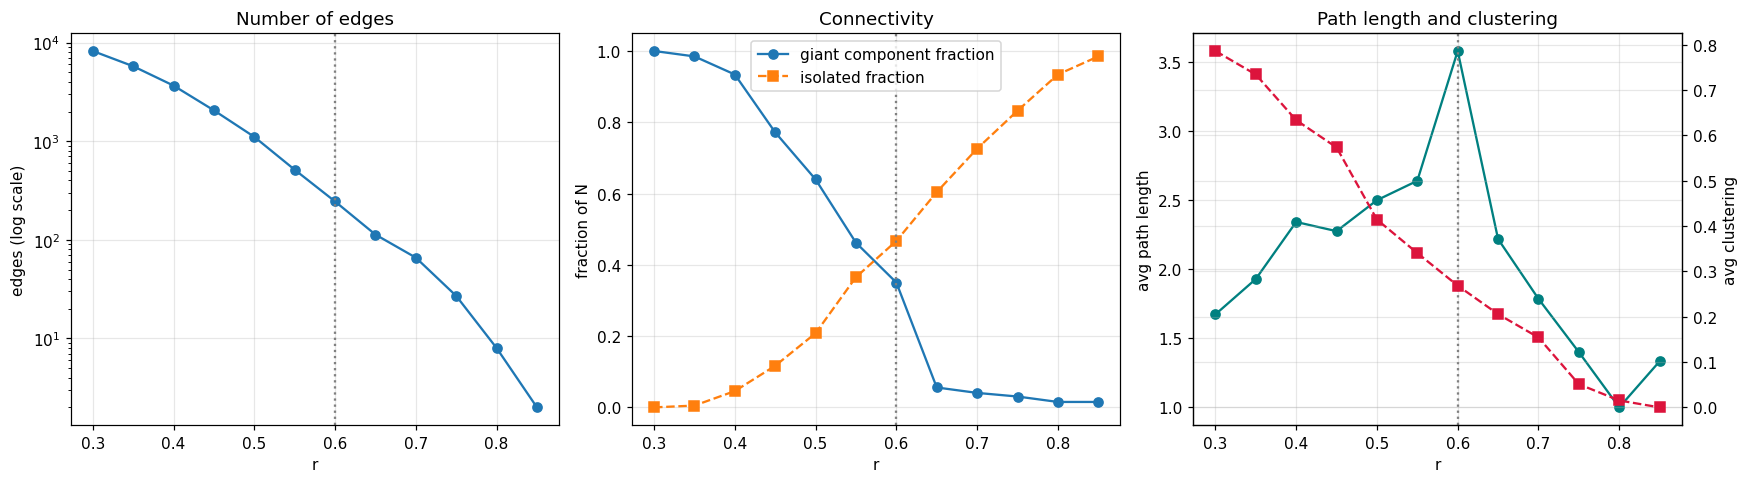

In [28]:
THRESHOLDS = np.round(np.arange(0.30, 0.86, 0.05), 2)
rows = []
for r in THRESHOLDS:
    Gr = build_graph(corr, r)
    comps_r = sorted(nx.connected_components(Gr), key=len, reverse=True)
    gc_r = Gr.subgraph(comps_r[0])
    apl = nx.average_shortest_path_length(gc_r) if len(gc_r) > 1 else np.nan
    h = homophily(Gr)[2] if Gr.number_of_edges() else np.nan
    rows.append({"r": r, "edges": Gr.number_of_edges(), "density": nx.density(Gr),
                 "isolated": nx.number_of_isolates(Gr), "components": len(comps_r),
                 "giant size": len(gc_r), "giant fraction": len(gc_r) / Gr.number_of_nodes(),
                 "avg path (giant)": apl, "avg clustering": nx.average_clustering(Gr),
                 "homophily ratio": h})
sens = pd.DataFrame(rows).set_index("r")
display(sens.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].semilogy(sens.index, sens["edges"], "o-")
ax[0].set(title="Number of edges", xlabel="r", ylabel="edges (log scale)")
ax[1].plot(sens.index, sens["giant fraction"], "o-", label="giant component fraction")
ax[1].plot(sens.index, sens["isolated"] / N, "s--", label="isolated fraction")
ax[1].set(title="Connectivity", xlabel="r", ylabel="fraction of N"); ax[1].legend()
ax[2].plot(sens.index, sens["avg path (giant)"], "o-", color="teal", label="avg path (giant)")
ax[2].set(title="Path length and clustering", xlabel="r", ylabel="avg path length")
ax2 = ax[2].twinx()
ax2.plot(sens.index, sens["avg clustering"], "s--", color="crimson", label="avg clustering")
ax2.set_ylabel("avg clustering")
for a in ax:
    a.axvline(r_main, color="grey", ls=":", label=f"r = {r_main}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/threshold_sensitivity.png", dpi=200)
plt.show()

## Exporting tables and key numbers for report

In [29]:
os.makedirs("results", exist_ok=True)
NA = "--"   # how missing values appear in the LaTeX tables

def save_tex(df, name, caption, label, fmt="%.3f", index=True):
    df.to_latex(f"{TAB_DIR}/{name}.tex", float_format=fmt, caption=caption,
                label=label, na_rep=NA, index=index, escape=True)

save_tex(quality, "data_quality", "Data quality and sample construction.", "tab:data_quality")
save_tex(pd.Series(summary, name="value").to_frame(), "graph_summary",
         "Basic properties of the unweighted network.", "tab:graph_summary", "%.4f")
for t, name, cap in zip(tables, ["top10_degree", "top10_betweenness", "top10_eigenvector"],
                        ["Top-10 stocks by degree centrality.",
                         "Top-10 stocks by betweenness centrality.",
                         "Top-10 stocks by eigenvector centrality."]):
    save_tex(t, name, cap, f"tab:{name}", "%.4f")
save_tex(cent.corr(method="spearman").round(3), "centrality_spearman",
         "Spearman rank correlation between centrality measures.", "tab:centrality_corr")
save_tex(fit, "degree_fit", "Degree distribution summary and tail-fit comparison.", "tab:degree_fit")

# Heavyweight ranks: fall back to a sentence if none of them is in the sample
if rank.empty:
    with open(f"{TAB_DIR}/heavyweight_ranks.tex", "w") as f:
        f.write(r"""\begin{table}
\caption{Centrality ranks of major index heavyweights.}
\label{tab:heavyweights}
\textit{None of the listed heavyweights is in the sample at this threshold.}
\end{table}
""")
else:
    save_tex(rank, "heavyweight_ranks", "Centrality ranks of major index heavyweights.",
             "tab:heavyweights", "%d")

save_tex(sector_tab.round(3).rename_axis(None), "sector_homophily",
         "Within-sector structure of the network.", "tab:sector_homophily")
save_tex(sens.round(3).rename(index=lambda x: f"{x:.2f}").rename_axis(None),
         "threshold_sensitivity", "Threshold sensitivity of network structure.", "tab:threshold")

key = {
    "window": [start, end], "N": int(N), "T": int(T), "r_main": r_main,
    "edges": int(G.number_of_edges()), "density": float(nx.density(G)),
    "alpha_mle": float(alpha_mle), "r2_exp": float(r2_exp), "r2_pow": float(r2_pow),
    "avg_clustering": float(avg_clust), "random_avg_clustering": float(rand_cc.mean()),
    "homophily_observed": float(obs), "homophily_expected": float(expected),
    "homophily_ratio": float(ratio), "permutation_p": float(p_val),
    "mp_edge": float(mp_edge), "largest_eigenvalue": float(eig[0]),
    "mean_pairwise_rho": float(off.mean()), "n_eig_above_mp": int((eig > mp_edge).sum()),
}
with open("results/summary.json", "w") as f:
    json.dump(key, f, indent=2)
print("Exported tables to", TAB_DIR, "and key numbers to results/summary.json")

Exported tables to tables and key numbers to results/summary.json
